In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# PARAMETRES

n = 5000                # nombre d'atomes

n_steps = 1000         # nombre de pas de temps
dt = 5e-14              # pas de temps

sigma = 4e-10           # distance interatomique
L = n*sigma             # longueur de la chaîne
kB = 1.38e-23
epsilon = 400           # 400 K = profondeur du puits

k = 72*epsilon*kB/(sigma**2)   # constante de raideur

M = 57e-3
N_Avogadro = 6.022e23
m = M / N_Avogadro      # masse de l'atome en kg => 9.5e-26 kg

T = 100
v_moy = np.sqrt(kB*T/m) # vitesse moyenne des particules en m/s

C = []                  # liste contenant toutes matrices d'état
E = []                  # liste contenant toutes les énergies mécaniques au cours du temps

In [57]:
# FONCTIONS

def calcul_accelerations(A, X, k, m, sigma):
    '''On fait le calcul à partir du bilan des forces sur la chaîne d'atomes.'''
    A[0] = k/m * (X[1] - X[0] - sigma)              # a_0 = k/m * (x_1 - x_0 - sigma)
    A[1:-1] = k/m * (X[2:] - 2*X[1:-1] + X[:-2])    # a_i = k/m * (x_(i+1) - 2x_i + x_(i-1))
    A[-1] = k/m * (X[-2] - X[-1] + sigma)           # a_(N-1) = k/m * (x_(N-2) - x_(N-1) + sigma)

    return A


# ALGORITHME DE VERLET VITESSE
def verlet_vitesse(C, dt, k, m, sigma):
    '''On fait une itération de l'algorithme de Verlet Vitesse. En entrée, la matrice d'état à t ; en sortie, la matrice d'état à t+dt.'''
    X, V, A = C[1], C[2], C[3]
    V_ij = V + A * dt/2
    X_n = X + V_ij * dt
    A_n = calcul_accelerations(np.zeros(n), X_n, k, m, sigma)
    V_n = V_ij + A_n * dt/2

    # Matrice d'état à t + dt
    C_n = np.stack((N, X_n, V_n, A_n))

    return C_n


def E_m(C):
    X, V = C[1], C[2]
    E_c = 1/2 * m * np.sum(V**2)
    # E_p = epsilon*(((sigma/V_n)**12) - 2*(sigma/V_n)**6) => potentiel de Lennard-Jones on le mettra parès
    E_p = 1/2 * k * np.sum((X[1:] - X[:-1] - sigma)**2)
    return E_c + E_p


def temperature_microcanonique(n, m, kB, V):
    T_sys = m / (n*kB)* np.sum(V**2)
    return T_sys


def autocorr_one_step(C_0, C_n):
    """Calcule gamma pour une étape."""
    v_0 = C_0[2]
    v_t = C_n[2]
    gamma = np.sum(v_0 * v_t)
    return gamma


def densite_etats(gamma):
    """Calcule la densité d'états vibrationnels g(w) à partir de la fonction d'autocorrélation gamma(t)"""
    N = len(gamma)
    
    g = np.abs(np.fft.rfft(gamma))
    omega = 2*np.pi*np.fft.rfftfreq(N, d=dt)

    # on normalise la densité d'états
    integrale = np.trapezoid(g, omega)
    g = g/integrale
    return omega, g

In [58]:
# INITIALISATION DES TABLEAUX

N = np.arange(n)                                        # tableau index
X = np.arange(0,L,sigma)                                # positions des particules
V = np.random.normal(loc=0, scale=v_moy, size=n)        # vitesse des particules
A = calcul_accelerations(np.zeros(n), X, k, m, sigma)   # accélération des particules

# Matrice d'état initiale
C_0 = np.stack((N,X,V,A))
C.append(C_0)
E.append(E_m(C_0))

In [59]:
# On fait tourner l'algorithme sur n_step itérations
C = [C_0]
E = [E_m(C_0)]
Autocorr_list = [autocorr_one_step(C_0, C_0)]
t = [0]

for i in range(1, n_steps):
    t.append(i*dt)

    C_i = verlet_vitesse(C[-1], dt, k, m, sigma)
    
    C.append(C_i)
    E.append(E_m(C_i))
    Autocorr_list.append(autocorr_one_step(C_0, C_i))

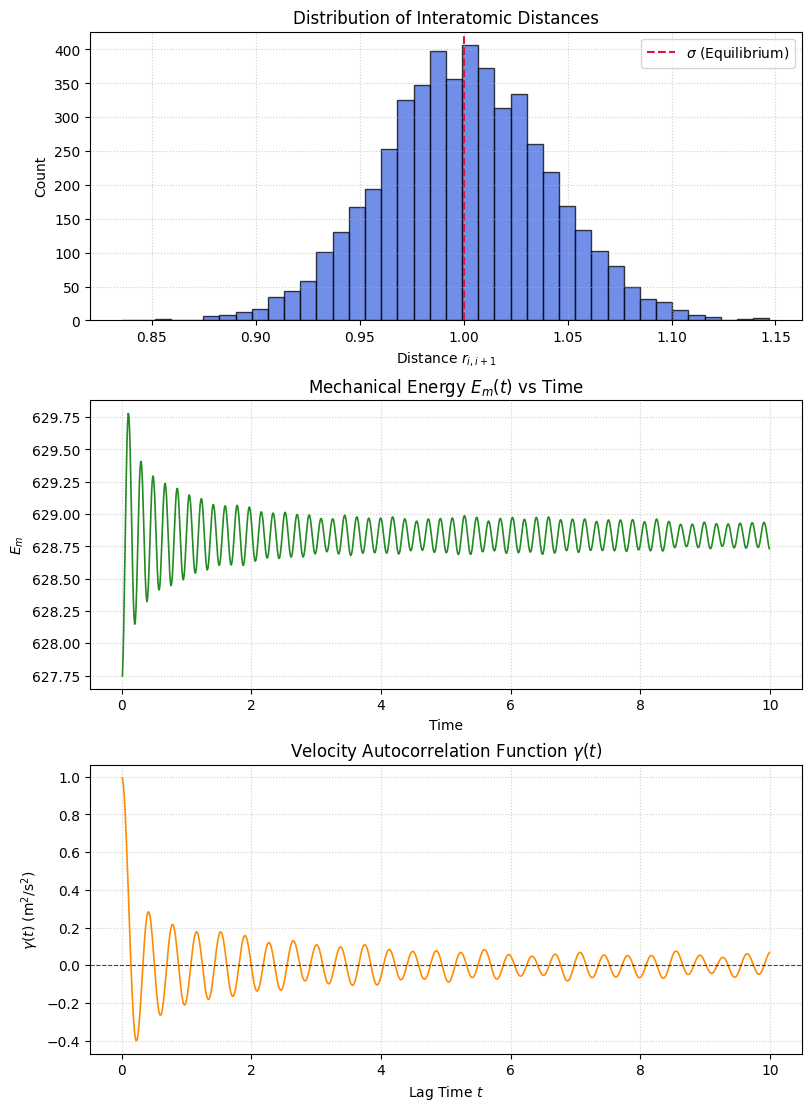

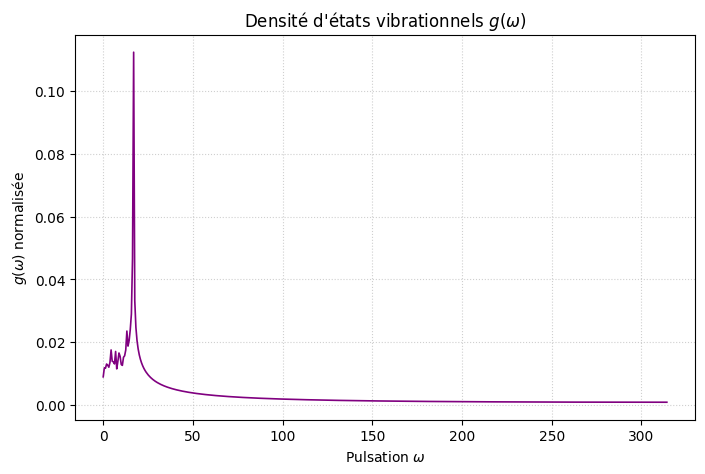

In [60]:
'''
print("Etat initial C :")
print(C[0])
print("\nEtat après 1 pas de l'algorithme")
print(C[-1])'''

# On trace la distribution des distances interatomiques
C_n = C[-1]
X_n = C_n[1]
a = []
for i in range(len(X_n)-1):
    a.append(X_n[i+1] - X_n[i])
    
    
t_plot = np.array(t[1:])
fig, axes = plt.subplots(3, 1, figsize=(8, 11), constrained_layout=True)

axes[0].hist(np.array(a), bins=40, color="royalblue", edgecolor="black", alpha=0.75)
axes[0].axvline(sigma, color="crimson", linestyle="--", linewidth=1.5, label=r"$\sigma$ (Equilibrium)")
axes[0].set_title("Distribution of Interatomic Distances", fontsize=12)
axes[0].set_xlabel(r"Distance $r_{i,i+1}$")
axes[0].set_ylabel("Count")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. Total Mechanical Energy Evolution
axes[1].plot(t_plot, E[1:], color="forestgreen", linewidth=1.2)
axes[1].set_title(r"Mechanical Energy $E_m(t)$ vs Time", fontsize=12)
axes[1].set_xlabel("Time")
axes[1].set_ylabel(r"$E_m$")
axes[1].grid(True, linestyle=":", alpha=0.6)

# 3. Velocity Autocorrelation Function (VACF)
axes[2].plot(t_plot, Autocorr_list[1:]/Autocorr_list[0], color="darkorange", linewidth=1.2)
axes[2].axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
axes[2].set_title(r"Velocity Autocorrelation Function $\gamma(t)$", fontsize=12)
axes[2].set_xlabel("Lag Time $t$")
axes[2].set_ylabel(r"$\gamma(t)$ (m$^2$/s$^2$)")
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.show()


omega, g_omega = densite_etats(Autocorr_list)
plt.figure(figsize=(8,5))
plt.plot(omega, g_omega, color="purple", linewidth=1.2)
plt.title(r"Densité d'états vibrationnels $g(\omega)$", fontsize=12)
plt.xlabel(r"Pulsation $\omega$")
plt.ylabel(r"$g(\omega)$ normalisée")
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()

In [61]:
# PARAMETRES ADIMENSIONES

n = 5000                # nombre d'atomes

n_steps = 1000         # nombre de pas de temps
dt = 0.01              # pas de temps

sigma = 1               # distance interatomique
L = n*sigma             # longueur de la chaîne
kB = 1
epsilon = 1             # profondeur du puits

k = 72*epsilon*kB/(sigma**2)   # constante de raideur

m = 1                   # masse de l'atome

T = 0.25                
v_moy = np.sqrt(kB*T/m) # vitesse moyenne des particules

C = []                  # liste contenant toutes matrices d'état
E = []                  # liste contenant toutes les énergies mécaniques au cours du temps